In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import os 
import sys 
sys.path.append('..')
import matplotlib.pyplot as plt 
import numpy as np
import torch
from pathlib import Path
from dotenv import load_dotenv
import pickle
from datetime import datetime
import time
from matplotlib.backends.backend_pdf import PdfPages
import pandas as pd

import hippocampalseq as hse
import hippocampalseq.utils as hseu
import hippocampalseq.preprocessing as hsep
import hippocampalseq.models as hsem
import hippocampalseq.plotting as hsepl
import hippocampalseq.analysis as hsea
from scipy.ndimage import gaussian_filter1d
import warnings


load_dotenv(Path.cwd().parent / ".env")
BASE_DIR = Path(os.environ["HSE_DATA_DIR"])
data_path = BASE_DIR
save_dir = BASE_DIR / "figures"

In [15]:
import hippocampalseq.analysis as hsea
print(hsea.__file__)
import hippocampalseq.analysis.postprocessing_sequences as psq
print(psq.__file__)
print([n for n in dir(psq) if not n.startswith('_')])

hsea.session_emissions = psq.session_emissions
hsea.grids_gaussian = psq.grids_gaussian
hsea.windows_from_firing_rate = psq.windows_from_firing_rate
hsea.peak_posterior= psq.peak_posterior
hsea.grids_map = psq.grids_map
hsea._two_troughs = psq._two_troughs

/project/bioinformatics/WZhang_lab/s437598/PO-OU/notebooks/../hippocampalseq/analysis/__init__.py
/project/bioinformatics/WZhang_lab/s437598/PO-OU/notebooks/../hippocampalseq/analysis/postprocessing_sequences.py
['MultivariateNormal', 'PdfPages', 'datetime', 'find_peaks', 'gaussian_filter1d', 'gaussian_to_grid', 'grids_gaussian', 'grids_map', 'hseu', 'identify_theta_sequence_windows', 'long_axis', 'moments_to_grid', 'np', 'os', 'peak_posterior', 'plt', 'save_all_figures', 'session_emissions', 'torch', 'warnings', 'weighted_fit', 'windows_from_firing_rate']


In [4]:
import sys, os, pickle, glob
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.append('..')
import hippocampalseq as hse
import hippocampalseq.analysis as hsea
import hippocampalseq.plotting as hsepl
import speed_analysis as spd
import path_length as pl


RUN_DATE   = "2026-09-23"
RUN_ROOT   = Path(os.environ["HSE_DATA_DIR"]) / "figures" / RUN_DATE / "naive_decoding"
pickle_dir = RUN_ROOT / "decoding_pickles"
MINOR_WINDOW, MAJOR_WINDOW = (80, 190), (200, 70)

In [5]:
def load_all_decoding(pickle_dir):
    pickle_dir = Path(pickle_dir)
    all_decoding = {}
    for p in sorted(pickle_dir.glob("*.pkl")):
        with open(p, "rb") as f:
            dec = pickle.load(f)
        all_decoding.setdefault(dec["rat_name"], {})[dec["session"]] = dec
    n = sum(len(v) for v in all_decoding.values())
    print(f"Loaded {n} sessions from {pickle_dir}")
    return all_decoding


def load_results(save_dir, *, percentile=None, decoder="emissions",
                pooling="per_session", tag=None):
    tag = tag or results_tag(percentile, decoder=decoder, pooling=pooling)
    with open(os.path.join(str(save_dir), f"{tag}.pkl"), "rb") as f:
        d = pickle.load(f)
    print(f"{sum(len(s) for s in d['all_results'].values())} sessions, "
        f"top {100 - d['spike_count_percentile']:.0f}% of cycles, "
        f"minor window {d['minor_window']}, "
        f"troughs {d['windows']['decoding_troughs_deg']}")
    return d


def results_tag(percentile, *, decoder="emissions", pooling="per_session"):
    """e.g. 'peak_posterior_top33_emissions_per_session'."""
    top = int(round(100 - percentile))          # 66.67 -> 33, 90 -> 10
    return f"peak_posterior_top{top}_{decoder}_{pooling}"

def run_all_peak_posterior(all_dec, count_window, *,
                        decoders=("emissions", "gaussian", "map"),
                        keys=(("both", None), ("pos", 1.0), ("neg", -1.0)),
                        phase_bin=10, minimum_max=0.01, velocity_cutoff=10.0, spike_count_percentile=90.0,     velocity_range=None):
    out = {}
    for rat, sessions in all_dec.items():
        out[rat] = {}
        for sess, data in sessions.items():
            t0 = time.perf_counter()
            env, seg, spk = data["environment_size"], data["ground_truth"], data["spikes"]
            bs, adv = data["bin_size_cm"], data["time_window_advance_s"]

            grids = {}
            if "emissions" in decoders: grids["emissions"] = data["emissions"]
            if "gaussian"  in decoders: grids["gaussian"]  = hsea.grids_gaussian(data["emissions"], env, bs)
            if "map"       in decoders: grids["map"]       = hsea.grids_map(data["emissions"])

            res = {d: {k: hsea.peak_posterior(g, env, seg, spk,
                            bin_size_cm=bs, phase_bin=phase_bin,
                            minimum_max=minimum_max, velocity_cutoff=velocity_cutoff, spike_count_percentile=spike_count_percentile,
                            count_window=count_window, step_s=adv, direction=dirn, verbose=True, velocity_range=None)
                       for k, dirn in keys}
                   for d, g in grids.items()}

            out[rat][sess] = {"results": res, "bimodal_fr": data["bimodal_fr"],
                              "rat_median_speed": data["rat_median_speed"]}
            n_win = sum(np.shape(e)[0] for e in data["emissions"])
            print(f"  {rat}/{sess}: {len(seg)} segments, {n_win} windows, "
                  f"{time.perf_counter()-t0:.1f}s", flush=True)
    return out


def pool_only(all_results, *, decoder="emissions", key="both", pooling="per_session"):
    stack = np.stack([s["results"][decoder][key]["dist_of_peak_post"]
                      for rat in all_results.values() for s in rat.values()], axis=-1)

    def _norm(a):
        col = a.sum(axis=0, keepdims=True)
        return a / np.where(col == 0, 1.0, col)

    if pooling == "per_session":
        return np.mean([_norm(stack[..., i]) for i in range(stack.shape[-1])], axis=0)
    if pooling == "raw_counts":
        return _norm(stack.sum(axis=-1))
    raise ValueError(pooling)


In [6]:
all_decoding = load_all_decoding(pickle_dir)
all_decoding = {r: s for r, s in all_decoding.items() if r != "Imp"}   # as in Fig 1B
win_1b = load_results(RUN_ROOT, percentile=66.67)["windows"]      # shared windows

Loaded 9 sessions from /work/bioinformatics/s437598/New_Brad_Data/_CleanDataSetForSharing/figures/2026-09-23/naive_decoding/decoding_pickles
9 sessions, top 33% of cycles, minor window (80, 190), troughs [65.0, 225.0]


30704 qualifying cycles across 8 sessions
         count        25%        50%        75%
rat                                            
Harpy  16268.0  24.030916  33.966853  44.586853
Janni  14436.0  20.841473  32.591118  55.316740
cutoff  20.0: 5774 slow / 24930 fast; fraction fast per rat {'Harpy': np.float64(0.85), 'Janni': np.float64(0.77)}
cutoff  25.0: 9554 slow / 21150 fast; fraction fast per rat {'Harpy': np.float64(0.73), 'Janni': np.float64(0.65)}
cutoff  30.0: 13070 slow / 17634 fast; fraction fast per rat {'Harpy': np.float64(0.6), 'Janni': np.float64(0.54)}


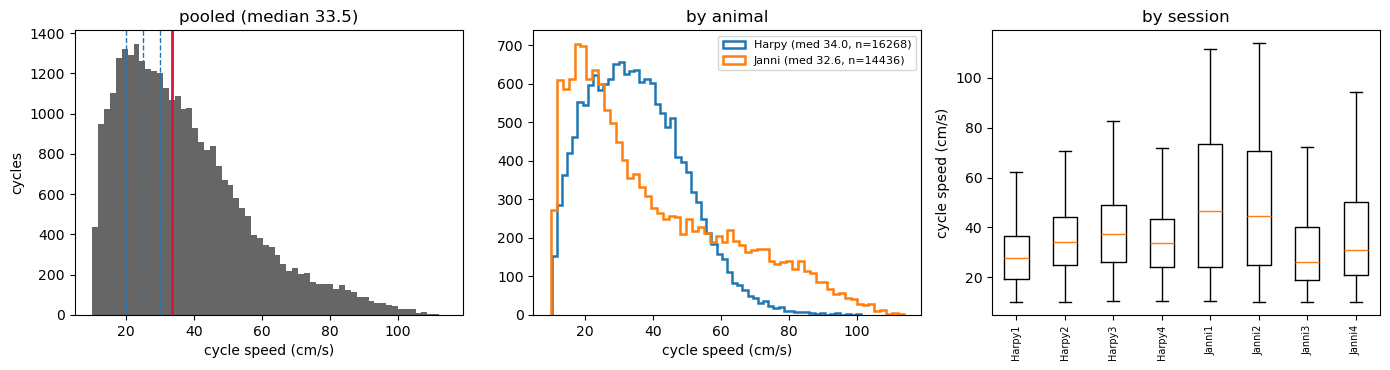

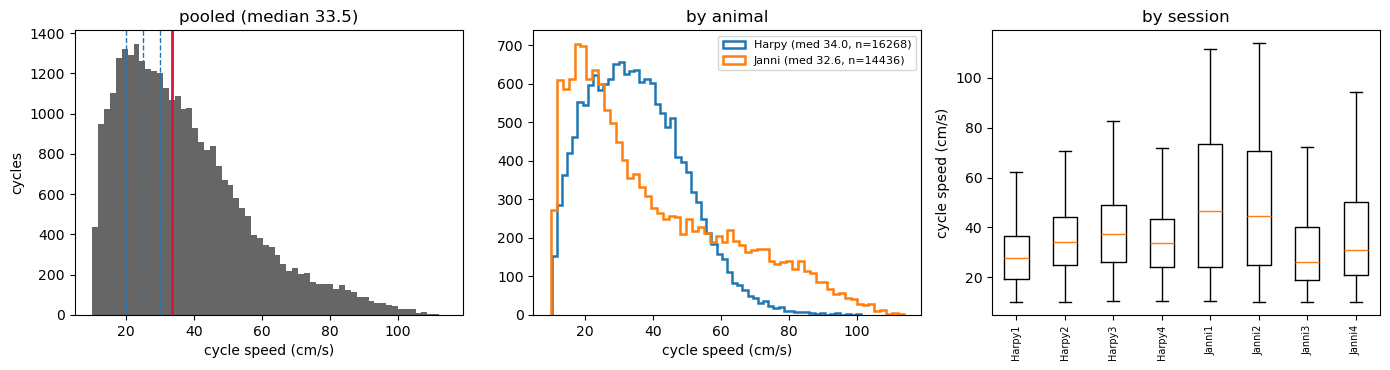

In [18]:
cycles = spd.cycle_table(all_decoding, MINOR_WINDOW)
spd.plot_speed_distributions(cycles)

In [19]:
spd.split_counts(cycles, 25.0)
spd.split_counts(cycles, None, per_animal=True)

split at 25.0 cm/s:
group          fast  slow
rat   session            
Harpy 1        1442  1066
      2        1586   525
      3        4838  1392
      4        3970  1449
Janni 1        1715   615
      2        2347   782
      3        2411  2105
      4        2841  1620
split at per-animal median:
group          fast  slow
rat   session            
Harpy 1         830  1678
      2        1069  1042
      3        3569  2661
      4        2666  2753
Janni 1        1508   822
      2        2009  1120
      3        1588  2928
      4        2113  2348


group          fast  slow
rat   session            
Harpy 1         830  1678
      2        1069  1042
      3        3569  2661
      4        2666  2753
Janni 1        1508   822
      2        2009  1120
      3        1588  2928
      4        2113  2348

In [20]:
print(cycles[["speed", "minor_spikes", "total_spikes"]].corr(method="spearman").round(3))
cycles.groupby(pd.qcut(cycles["speed"], 5))["minor_spikes"].median()

              speed  minor_spikes  total_spikes
speed         1.000         0.168         0.181
minor_spikes  0.168         1.000         0.770
total_spikes  0.181         0.770         1.000


/tmp/ipykernel_2621482/2056265521.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cycles.groupby(pd.qcut(cycles["speed"], 5))["minor_spikes"].median()


speed
(10.083, 20.5]       18.0
(20.5, 28.894]       19.0
(28.894, 38.53]      19.0
(38.53, 51.732]      19.0
(51.732, 113.863]    28.0
Name: minor_spikes, dtype: float64

In [8]:
CUT = 25.0
groups = {"slow": (10.0, CUT), "fast": (CUT, np.inf)}

In [18]:
import importlib
import hippocampalseq.analysis as hsea
importlib.reload(hsea)

GROUPS = {"slow": (10.0, 32.0), "fast": (32.0, 1e9)}
minor = minor = (80, 190)        # whatever you used for Fig 1B

results = {}
for label, vr in GROUPS.items():
    per_session = {}
    for rat, sessions in all_decoding.items():
        for sess, data in sessions.items():
            per_session[(rat, sess)] = hsea.peak_posterior(
                data["emissions"],
                data["environment_size"],
                data["ground_truth"],
                data["spikes"],
                bin_size_cm=data["bin_size_cm"],
                count_window=minor,
                velocity_range=vr,
                verbose=False)
    results[label] = per_session
    n = sum(r["n_oscillations_used"] for r in per_session.values())
    print(f"{label}: {n} cycles used")

slow: 5010 cycles used
fast: 5682 cycles used


2508 oscillations pass flags; 267 selected (>= 43 spikes in (80, 190))
1828 oscillations pass flags; 190 selected (>= 44 spikes in (80, 190))
680 oscillations pass flags; 69 selected (>= 43 spikes in (80, 190))
2508 oscillations pass flags; 267 selected (>= 43 spikes in (80, 190))
1828 oscillations pass flags; 190 selected (>= 44 spikes in (80, 190))
680 oscillations pass flags; 69 selected (>= 43 spikes in (80, 190))
2508 oscillations pass flags; 267 selected (>= 43 spikes in (80, 190))
1828 oscillations pass flags; 190 selected (>= 44 spikes in (80, 190))
680 oscillations pass flags; 69 selected (>= 43 spikes in (80, 190))
  Harpy/1: 86 segments, 66579 windows, 26.8s
2111 oscillations pass flags; 216 selected (>= 49 spikes in (80, 190))
1569 oscillations pass flags; 157 selected (>= 47 spikes in (80, 190))
542 oscillations pass flags; 59 selected (>= 51 spikes in (80, 190))
2111 oscillations pass flags; 216 selected (>= 49 spikes in (80, 190))
1569 oscillations pass flags; 157 select

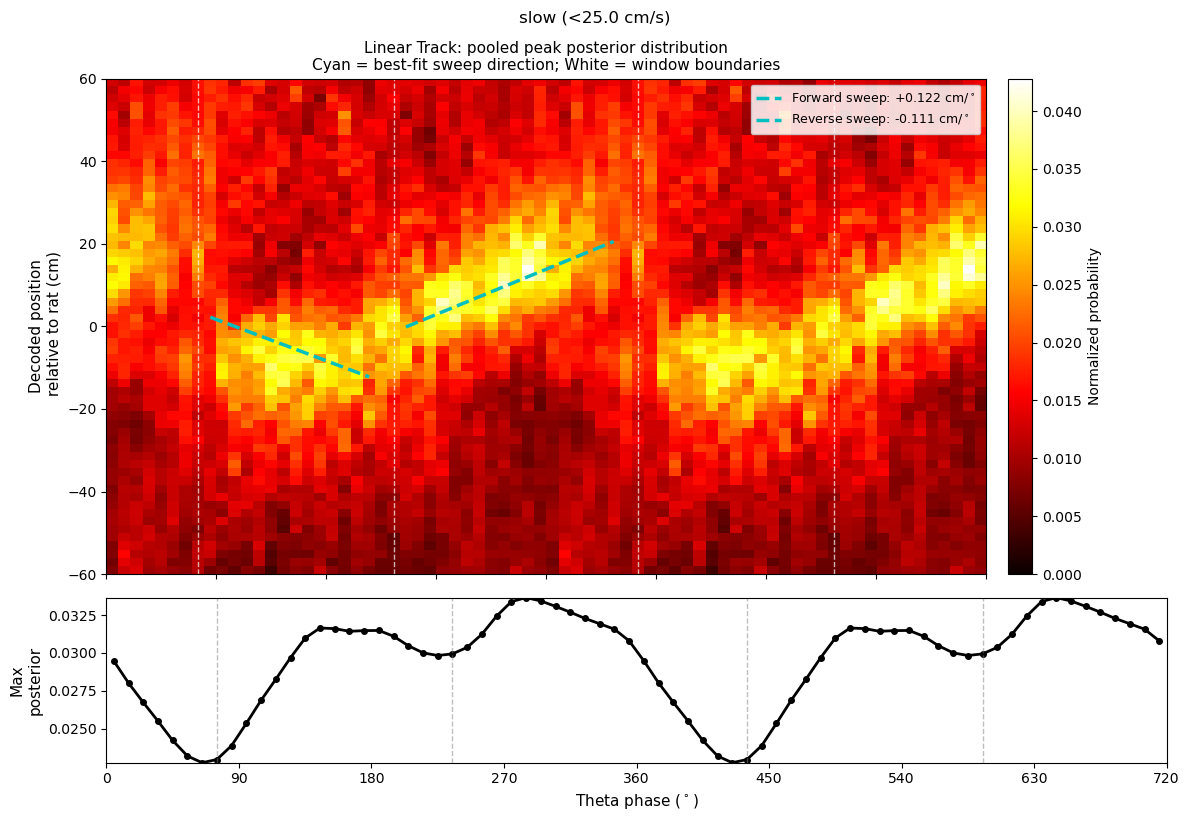

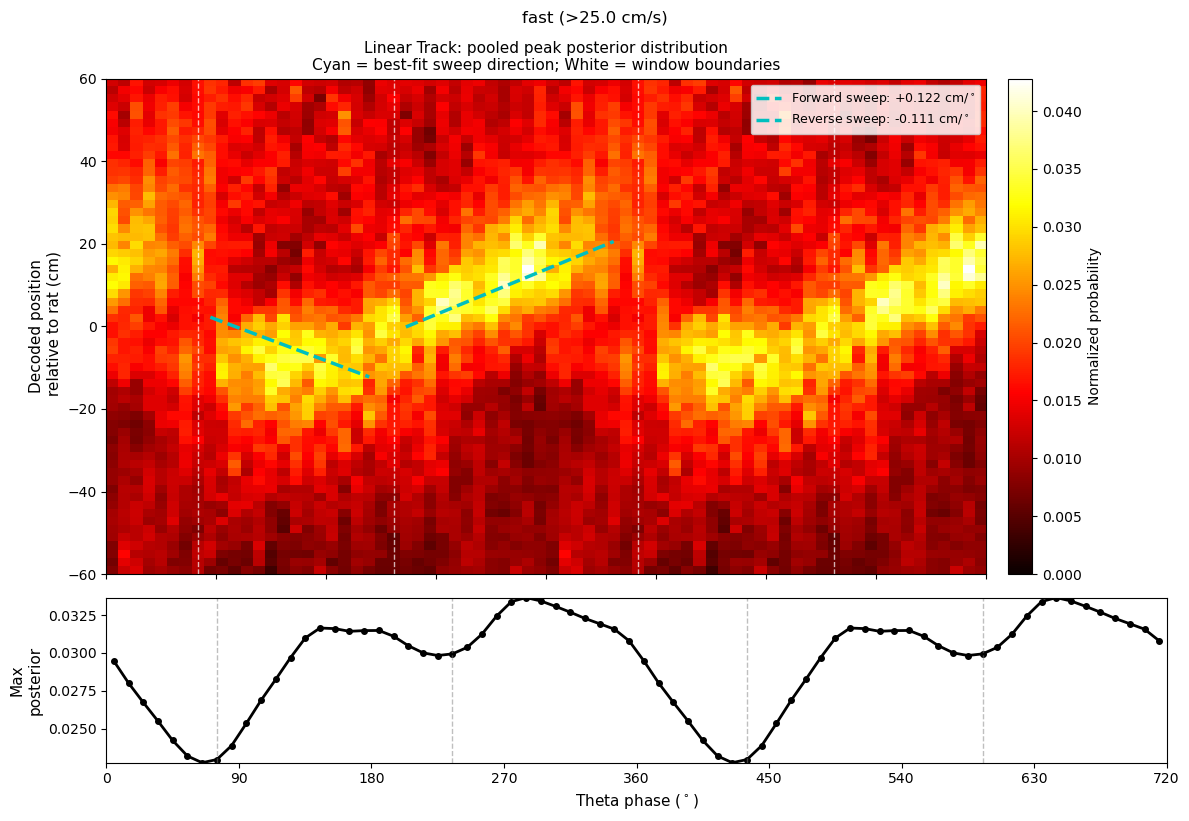

In [10]:
figs = {}
for label, vr in groups.items():
    res = run_all_peak_posterior(all_decoding, MINOR_WINDOW, velocity_range=vr)
    p = pool_only(res, decoder="emissions", pooling="per_session")
    fig = hsepl.plot_across_session_decoding_hist(
        win_1b["max_prob_trace"], p,
        forward_window=tuple(win_1b["forward_window"]),
        reverse_window=tuple(win_1b["reverse_window"]),
        fit_method="argmax")
    fig.suptitle(f"{label} (<{CUT} cm/s)" if label == "slow" else f"{label} (>{CUT} cm/s)", y=1.02)
    figs[label] = fig

In [9]:
for label, vr in groups.items():
    res = run_all_peak_posterior(all_decoding, MINOR_WINDOW, velocity_range=vr)
    p = pool_only(res, decoder="emissions", pooling="per_session")
    print(label, vr, "n_cycles",
          sum(r["results"]["emissions"]["both"]["n_oscillations_used"]
              for s in res.values() for r in s.values()),
          "map sum", float(p.sum()))

2508 oscillations pass flags; 267 selected (>= 43 spikes in (80, 190))
1828 oscillations pass flags; 190 selected (>= 44 spikes in (80, 190))
680 oscillations pass flags; 69 selected (>= 43 spikes in (80, 190))
2508 oscillations pass flags; 267 selected (>= 43 spikes in (80, 190))
1828 oscillations pass flags; 190 selected (>= 44 spikes in (80, 190))
680 oscillations pass flags; 69 selected (>= 43 spikes in (80, 190))
2508 oscillations pass flags; 267 selected (>= 43 spikes in (80, 190))
1828 oscillations pass flags; 190 selected (>= 44 spikes in (80, 190))
680 oscillations pass flags; 69 selected (>= 43 spikes in (80, 190))
  Harpy/1: 86 segments, 66579 windows, 27.4s
2111 oscillations pass flags; 216 selected (>= 49 spikes in (80, 190))
1569 oscillations pass flags; 157 selected (>= 47 spikes in (80, 190))
542 oscillations pass flags; 59 selected (>= 51 spikes in (80, 190))
2111 oscillations pass flags; 216 selected (>= 49 spikes in (80, 190))
1569 oscillations pass flags; 157 select

In [19]:
import numpy as np

def pool(per_session):
    maps = []
    for r in per_session.values():
        m = np.asarray(r["dist_of_peak_post"], float)
        col = m.sum(axis=0, keepdims=True)
        maps.append(m / np.where(col == 0, 1.0, col))
    return np.mean(maps, axis=0)

pooled = {k: pool(v) for k, v in results.items()}

In [23]:
major = (minor[1], minor[0])
all_pooled = pool({**results["slow"], **results["fast"]})
win = hsea.identify_theta_sequence_windows(
        all_pooled, minor_window=minor, major_window=major)
print("troughs", win["decoding_troughs_deg"])
print("forward", win["forward_window"], "reverse", win["reverse_window"])

troughs [65.0, 225.0]
forward [np.float64(235.0), np.float64(55.0)] reverse [np.float64(75.0), np.float64(215.0)]


In [32]:
EDGES = [10, 20, 30, 40, 50, 1e9]
labels = [f"{a:.0f}-{b:.0f}" if b < 1e8 else f"{a:.0f}+"
          for a, b in zip(EDGES[:-1], EDGES[1:])]

binned = {}
for lab, a, b in zip(labels, EDGES[:-1], EDGES[1:]):
    per_session = {}
    for rat, sessions in all_decoding.items():
        for sess, data in sessions.items():
            per_session[(rat, sess)] = hsea.peak_posterior(
                data["emissions"], data["environment_size"],
                data["ground_truth"], data["spikes"],
                bin_size_cm=data["bin_size_cm"], count_window=minor,
                velocity_range=(a, b), verbose=False)
    binned[lab] = per_session
    print(f"{lab:>7} cm/s: {sum(r['n_oscillations_used'] for r in per_session.values())} cycles")

  10-20 cm/s: 1997 cycles
  20-30 cm/s: 2516 cycles
  30-40 cm/s: 2206 cycles
  40-50 cm/s: 1605 cycles
    50+ cm/s: 2330 cycles


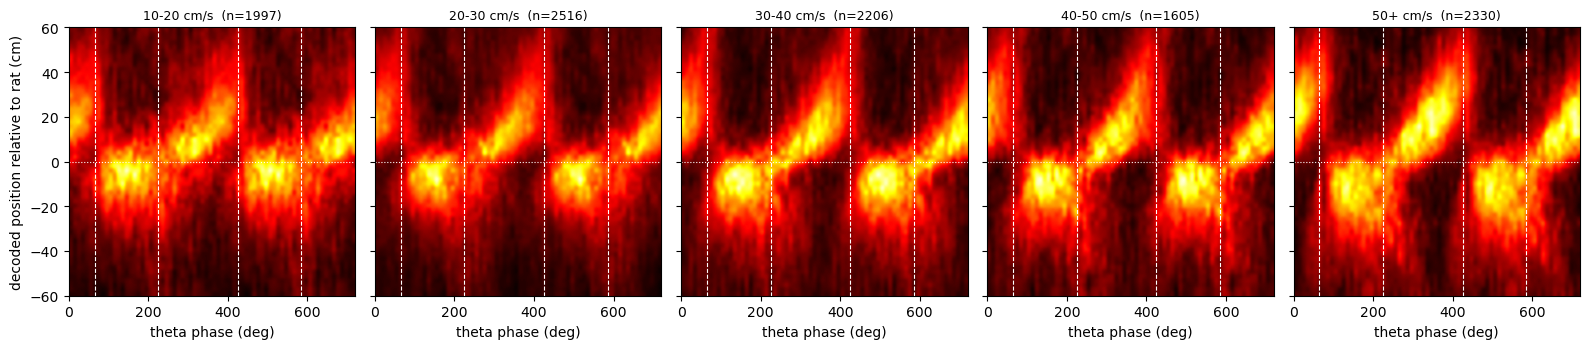

In [33]:
import matplotlib.pyplot as plt

def pool(per_session):
    ms = []
    for r in per_session.values():
        m = np.asarray(r["dist_of_peak_post"], float)
        c = m.sum(axis=0, keepdims=True)
        ms.append(m / np.where(c == 0, 1.0, c))
    return np.mean(ms, axis=0)

n = len(labels)
fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.6), squeeze=False, sharey=True)
for ax, lab in zip(axes[0], labels):
    m = pool(binned[lab])
    ax.imshow(np.tile(m, (1, 2)), origin="lower", aspect="auto", cmap="hot",
              extent=[0, 720, -60, 60], interpolation="gaussian")
    for w in win["decoding_troughs_deg"]:
        for k in (0, 360):
            ax.axvline(w + k, color="w", ls="--", lw=.8)
    ax.axhline(0, color="w", ls=":", lw=.8)
    n_cyc = sum(r["n_oscillations_used"] for r in binned[lab].values())
    ax.set_title(f"{lab} cm/s  (n={n_cyc})", fontsize=9)
    ax.set_xlabel("theta phase (deg)")
axes[0][0].set_ylabel("decoded position relative to rat (cm)")
fig.tight_layout()


wrote theta_sequences_by_speed.pdf (1 page)
wrote figure_1b_all_cycles.pdf (1 page)


'figure_1b_all_cycles.pdf'

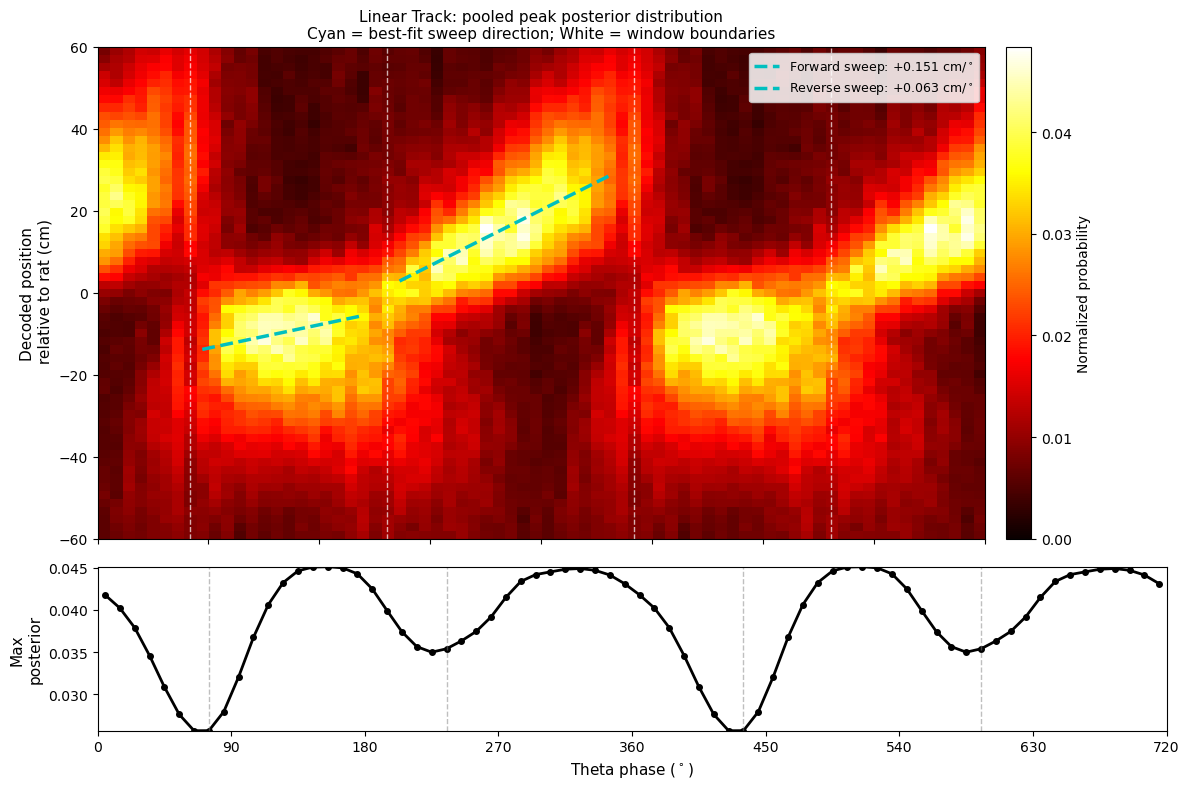

In [35]:
# speed-binned grid — `fig` is the figure you just made
pl.save_pdf(fig, "theta_sequences_by_speed.pdf")

# Figure 1B, all cycles pooled
f1b = hsepl.plot_across_session_decoding_hist(
        win["max_prob_trace"], all_pooled,
        win["forward_window"], win["reverse_window"],
        phase_bin=10, position_bin=2, fit_method="argmax")

if not hasattr(f1b, "savefig"):          # if it doesn't return the figure
    import matplotlib.pyplot as plt
    f1b = plt.gcf()

pl.save_pdf(f1b, "figure_1b_all_cycles.pdf")

In [34]:
pl.save_pdf([f1b, fig], "theta_sequences.pdf")   # page 1 = Fig 1B, page 2 = speed grid

wrote theta_sequences.pdf (2 pages)


'theta_sequences.pdf'